# MAE — Can one-step health predictors roll forward within a video clip?

**COMPLETE · Within-clip forecast and action-identification pilot complete**  
Updated 2026-11-18T14:04:54.930401+01:00. Branches 648/648; **ETA 2026-11-18T14:04:54.930401+01:00** (Stockholm).

E203 continues on the Windows PC. This independent MAE study runs on the remote Tesla T4.

## Question and controlled test

Good one-step RMSE does not establish that a predictor can simulate a training trajectory. We forecast from frame32 of a96-frame clip and compare with actual matched MAE branches over the next64 frames. Skip,0.25× and1× apply on **each** future arrival. Three future mask draws are paired across actions. All readouts remain inside the source clip.

The24 selected clips split chronologically into12 fit,6 validation and6 test clips. Three leave-one-seed-out folds train only on the other source seeds and fit clips. Hyperparameters follow the earlier predictor benchmark; labels are absent.

## What is predicted

Reconstruction MSE, uncentered RankMe and mean feature variance are separate targets on two fixed banks: 32 already-observed frames from this clip and128 older calibration frames. A bank never refreshes inside a branch, and its assay mask is fixed. Thus Skip has exactly zero change. Centered rank is recorded as a diagnostic. Raw ranks from different bank sizes are not directly comparable.

The recursive predictor advances its own six predicted health values. Causal prefix/context features stay fixed at the origin, while known elapsed time advances. Future measured features are never substituted. This is a new rollable state representation: old37/88-input weights cannot simply be reused for changed targets. The MAE recipe, action rates, predictor families and fixed hyperparameter recipes are reused.

## Comparisons and interpretation

Persistence and action-wise mean-delta extrapolation are baselines. Ridge, Lasso, MLP, XGBoost and Random forest are fitted as recursive one-step and direct horizon-conditioned models. Teacher-forced one-step errors use the true preceding health state **only as a diagnostic**. They are not open-loop forecasts.

Plots report RMSE for **loss, rank and variance** versus horizons1/2/4/8/16/32/64, normalized error against persistence, action-ranking accuracy and realized regret. Skip is excluded from primary RMSE because its zero transition is known, but included in action-selection analysis. Independent-draw oracle selection uses two draws and is evaluated on the third. Noisy oracle gains, tied actions and six held-out clips constrain interpretation. Rank or variance gains alone are not evidence of semantic learning.

The source learner and optimizer resume from the original8000-arrival calibration, then follow a new fixed-quarter trajectory on this GPU. Cross-device bit identity is not assumed. Identical-mask reproduction and exact state restoration are checked on this host. Checkpoints are atomic and resume after a disconnect or restart.


## Held-out source seeds and clips

| Model | Forecast | Horizon | Local MSE RMSE | Local RankMe RMSE | Local variance RMSE |
| --- | --- | --- | --- | --- | --- |
| Action-wise delta | baseline | 1 | 0.00564626 | 0.00222176 | 8.8857e-05 |
| Action-wise delta | baseline | 16 | 0.0430903 | 0.0257991 | 0.0012791 |
| Action-wise delta | baseline | 64 | 0.0684079 | 0.0829075 | 0.00413084 |
| Lasso | direct | 1 | 0.0642087 | 0.0814283 | 0.00240327 |
| Lasso | direct | 16 | 0.0523262 | 0.082941 | 0.00216204 |
| Lasso | direct | 64 | 0.0493377 | 0.113371 | 0.00429933 |
| Lasso | recursive | 1 | 0.00574516 | 0.00412751 | 0.00025687 |
| Lasso | recursive | 16 | 0.0622043 | 0.0568819 | 0.00331102 |
| Lasso | recursive | 64 | 0.134268 | 0.17142 | 0.00799988 |
| Lasso | teacher-forced diagnostic | 1 | 0.00574516 | 0.00412751 | 0.00025687 |
| Lasso | teacher-forced diagnostic | 16 | 0.00517185 | 0.00485422 | 0.000301351 |
| Lasso | teacher-forced diagnostic | 64 | 0.00688372 | 0.00646385 | 0.000337322 |
| MLP | direct | 1 | 0.0669928 | 0.042827 | 0.00276102 |
| MLP | direct | 16 | 0.0681134 | 0.0456353 | 0.00328137 |
| MLP | direct | 64 | 0.0677242 | 0.103861 | 0.00471897 |
| MLP | recursive | 1 | 0.00644083 | 0.00551626 | 0.000295639 |
| MLP | recursive | 16 | 0.0809878 | 0.0776164 | 0.00372838 |
| MLP | recursive | 64 | 0.265394 | 0.247995 | 0.00982936 |
| MLP | teacher-forced diagnostic | 1 | 0.00644083 | 0.00551626 | 0.000295639 |
| MLP | teacher-forced diagnostic | 16 | 0.00429068 | 0.00493867 | 0.000242432 |
| MLP | teacher-forced diagnostic | 64 | 0.00393635 | 0.00484637 | 0.000312938 |
| Persistence | baseline | 1 | 0.00707125 | 0.00224756 | 8.81098e-05 |
| Persistence | baseline | 16 | 0.0643382 | 0.0273632 | 0.00133953 |
| Persistence | baseline | 64 | 0.0725546 | 0.0836289 | 0.00401713 |
| Random forest | direct | 1 | 0.0314499 | 0.015193 | 0.00127477 |
| Random forest | direct | 16 | 0.0372957 | 0.0329126 | 0.0027501 |
| Random forest | direct | 64 | 0.047505 | 0.0840076 | 0.00401129 |
| Random forest | recursive | 1 | 0.00408892 | 0.00254673 | 8.79634e-05 |
| Random forest | recursive | 16 | 0.0373989 | 0.0279857 | 0.00102801 |
| Random forest | recursive | 64 | 0.0537987 | 0.0941932 | 0.00390571 |
| Random forest | teacher-forced diagnostic | 1 | 0.00408892 | 0.00254673 | 8.79634e-05 |
| Random forest | teacher-forced diagnostic | 16 | 0.00180166 | 0.00346174 | 0.000151267 |
| Random forest | teacher-forced diagnostic | 64 | 0.00318832 | 0.00307399 | 0.00015919 |
| Ridge | direct | 1 | 0.132394 | 0.186664 | 0.0117238 |
| Ridge | direct | 16 | 0.120029 | 0.172199 | 0.0111931 |
| Ridge | direct | 64 | 0.111206 | 0.195221 | 0.0119996 |
| Ridge | recursive | 1 | 0.00857486 | 0.00526647 | 0.000452799 |
| Ridge | recursive | 16 | 0.0953618 | 0.0756963 | 0.00596797 |
| Ridge | recursive | 64 | 0.1696 | 0.260179 | 0.0146079 |
| Ridge | teacher-forced diagnostic | 1 | 0.00857486 | 0.00526647 | 0.000452799 |
| Ridge | teacher-forced diagnostic | 16 | 0.00820512 | 0.00632277 | 0.000529716 |
| Ridge | teacher-forced diagnostic | 64 | 0.00947176 | 0.00810966 | 0.000562436 |
| XGBoost | direct | 1 | 0.00984169 | 0.0109508 | 0.000385392 |
| XGBoost | direct | 16 | 0.0308134 | 0.0503131 | 0.00122811 |
| XGBoost | direct | 64 | 0.0380766 | 0.093432 | 0.00394964 |
| XGBoost | recursive | 1 | 0.00392328 | 0.00384398 | 0.000366218 |
| XGBoost | recursive | 16 | 0.0336996 | 0.0401537 | 0.00332597 |
| XGBoost | recursive | 64 | 0.0433403 | 0.105493 | 0.00960983 |
| XGBoost | teacher-forced diagnostic | 1 | 0.00392328 | 0.00384398 | 0.000366218 |
| XGBoost | teacher-forced diagnostic | 16 | 0.00152629 | 0.00340962 | 0.000275086 |
| XGBoost | teacher-forced diagnostic | 64 | 0.00293834 | 0.00388165 | 0.000263742 |

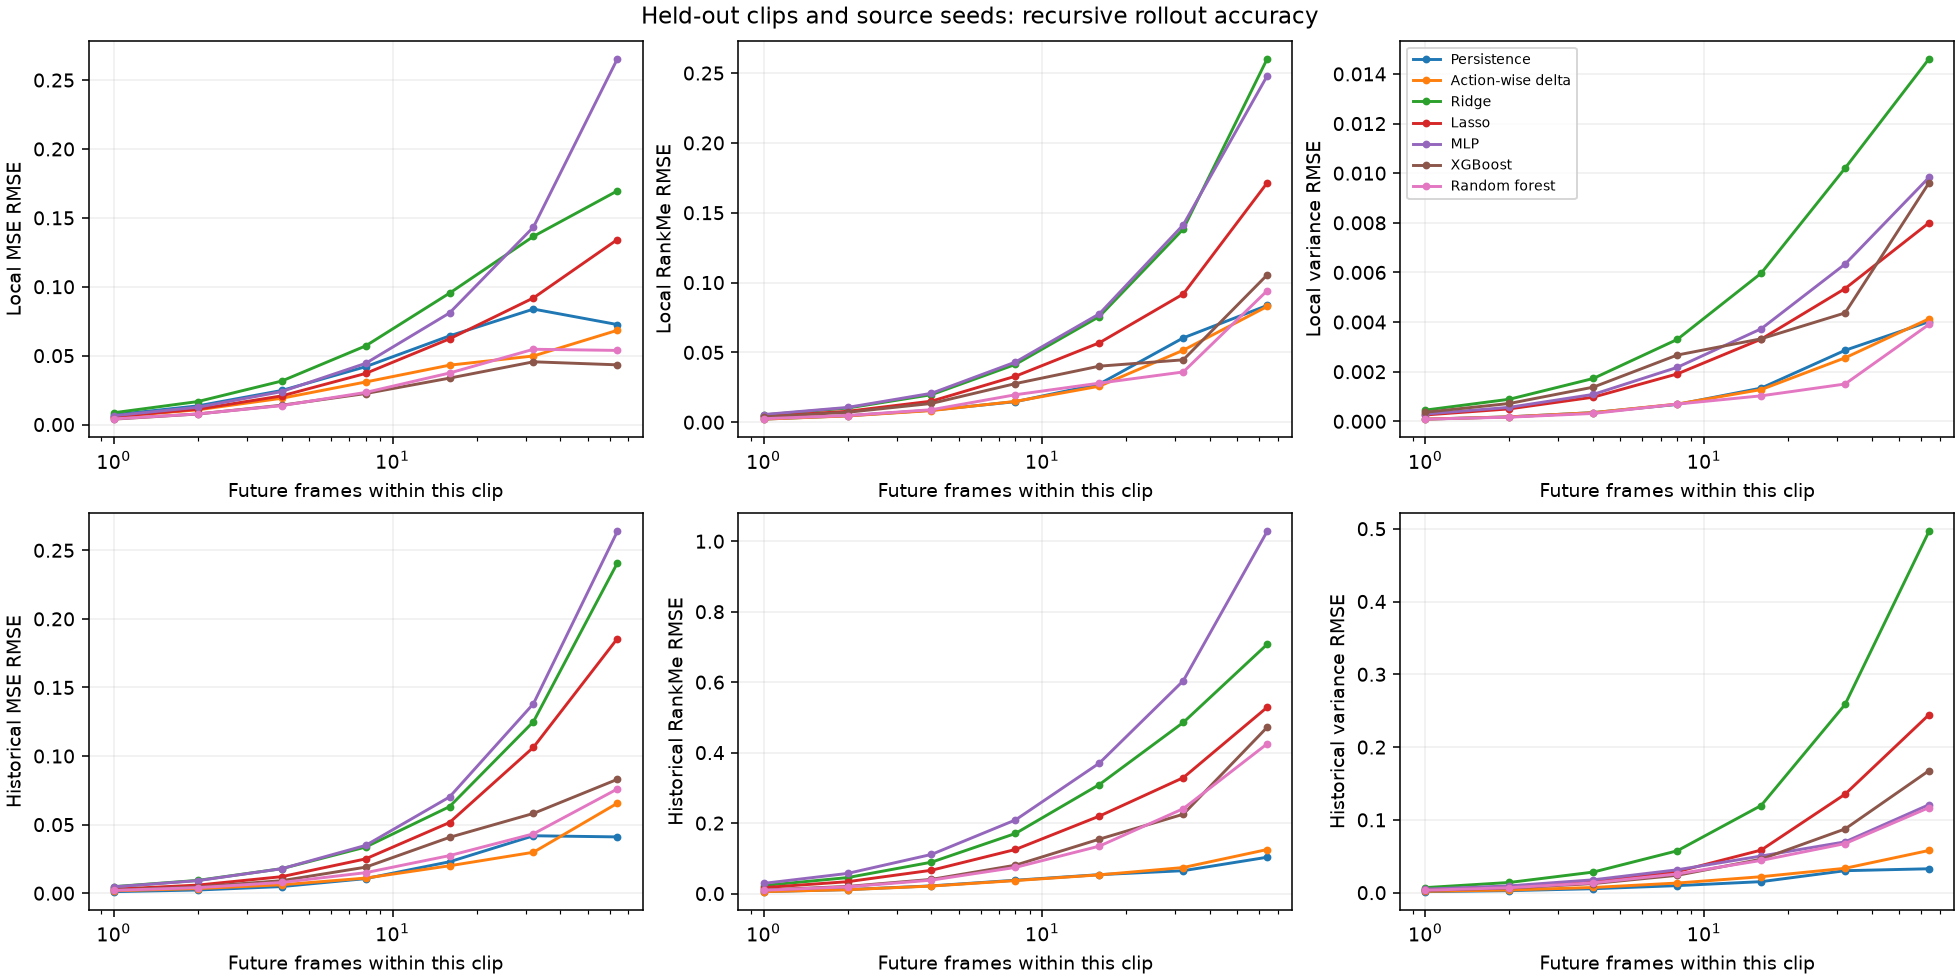

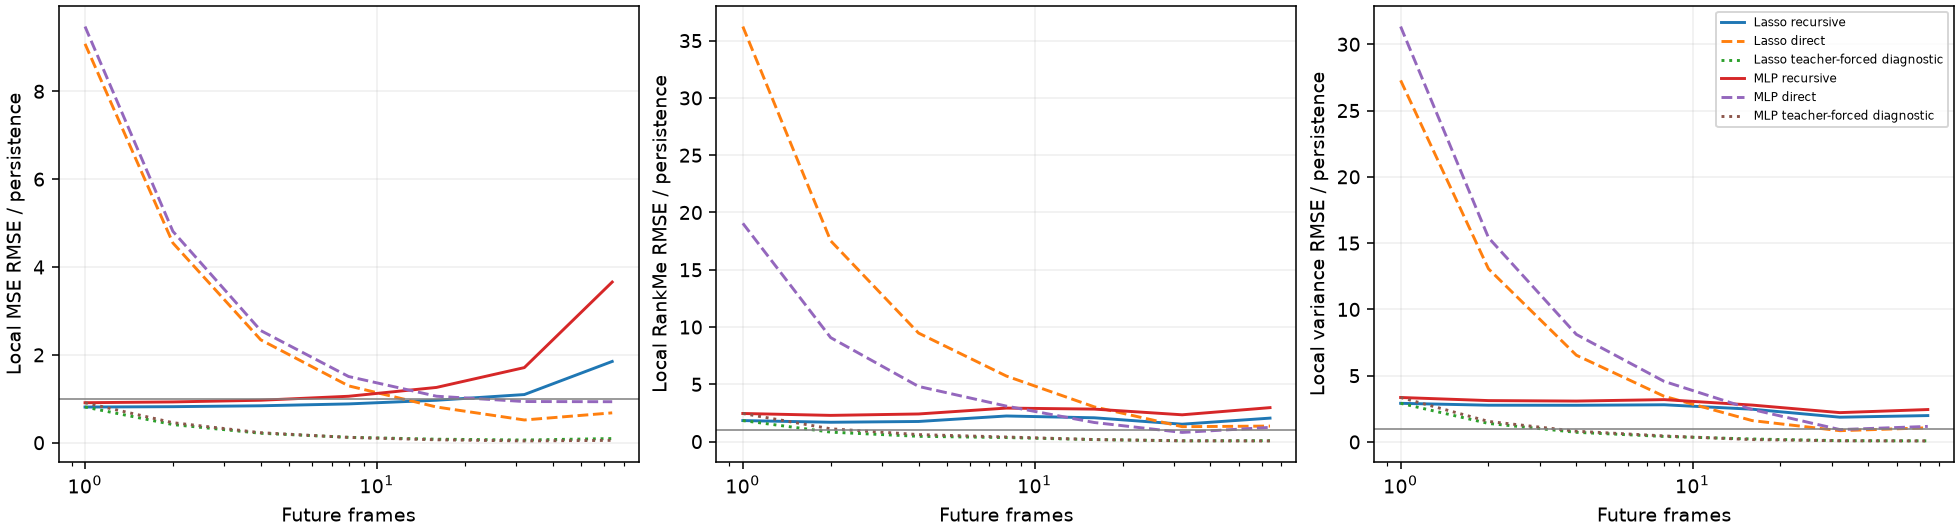

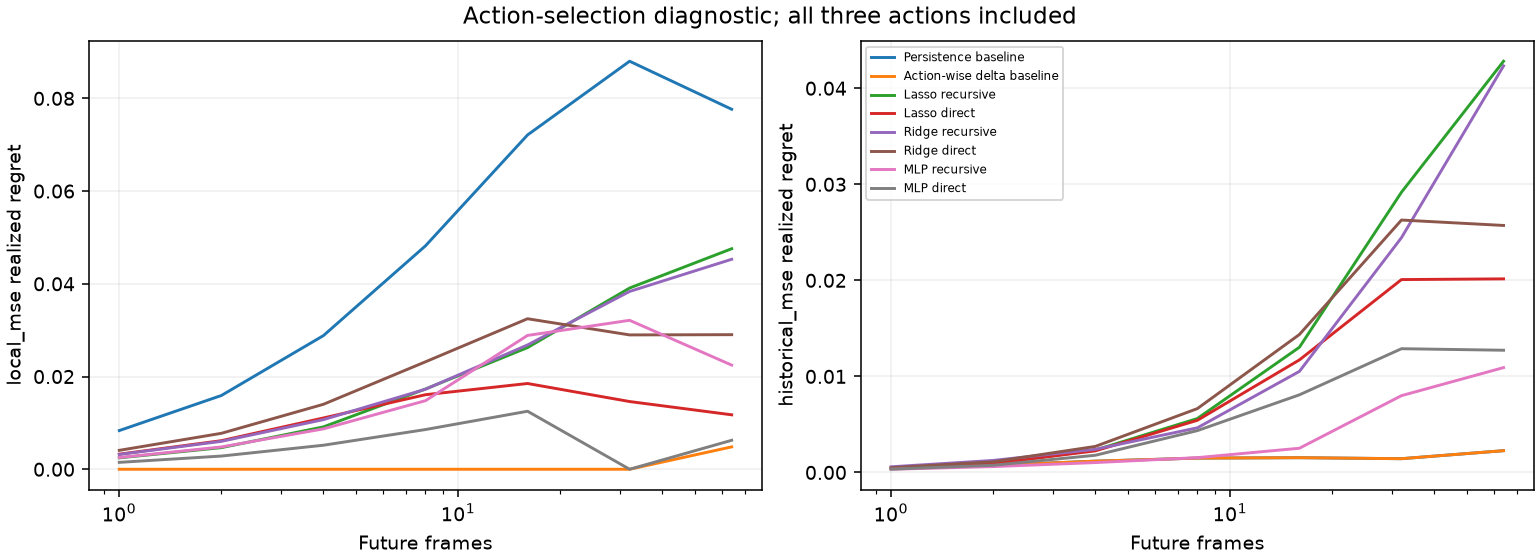